# Example of the aitlas toolbox in the context of object detection 

This notebook shows a sample implementation of object detection using the aitlas toolbox. The RarePlanes dataset contains airplane annotations in geojson format. 

## Import the required packages

In [ ]:
from aitlas.datasets import RarePlanesDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

In [42]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/RarePlanes/train/PS-RGB_tiled",
    "annotation_dir": "/home/dragik/data/FAIR_EO/RarePlanes/train/geojson_aircraft_tiled"
}
dataset = RarePlanesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 5815


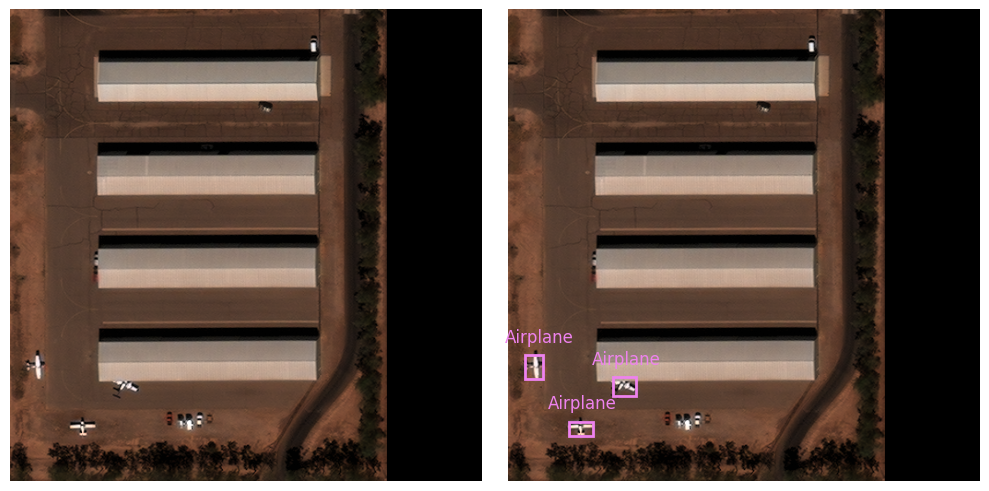

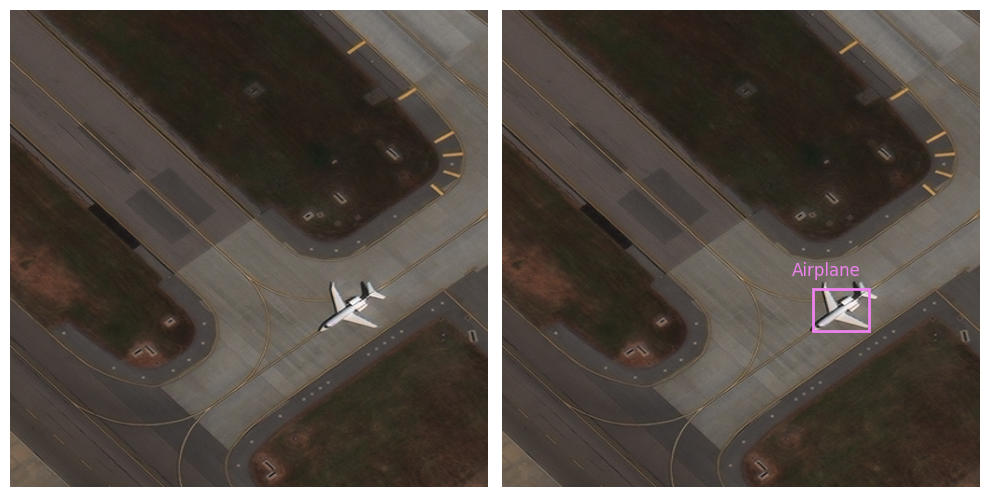

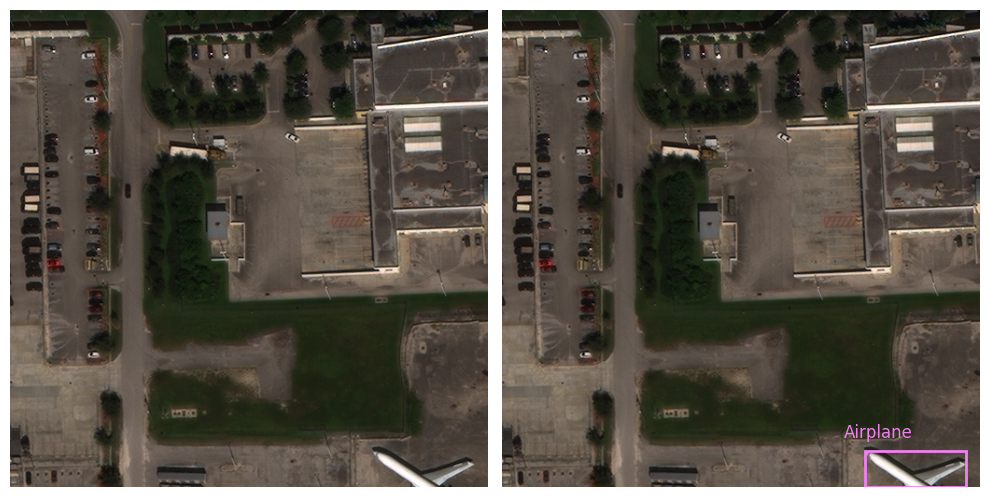

In [43]:
dataset.show_image(50);
dataset.show_image(10);
dataset.show_image(200);

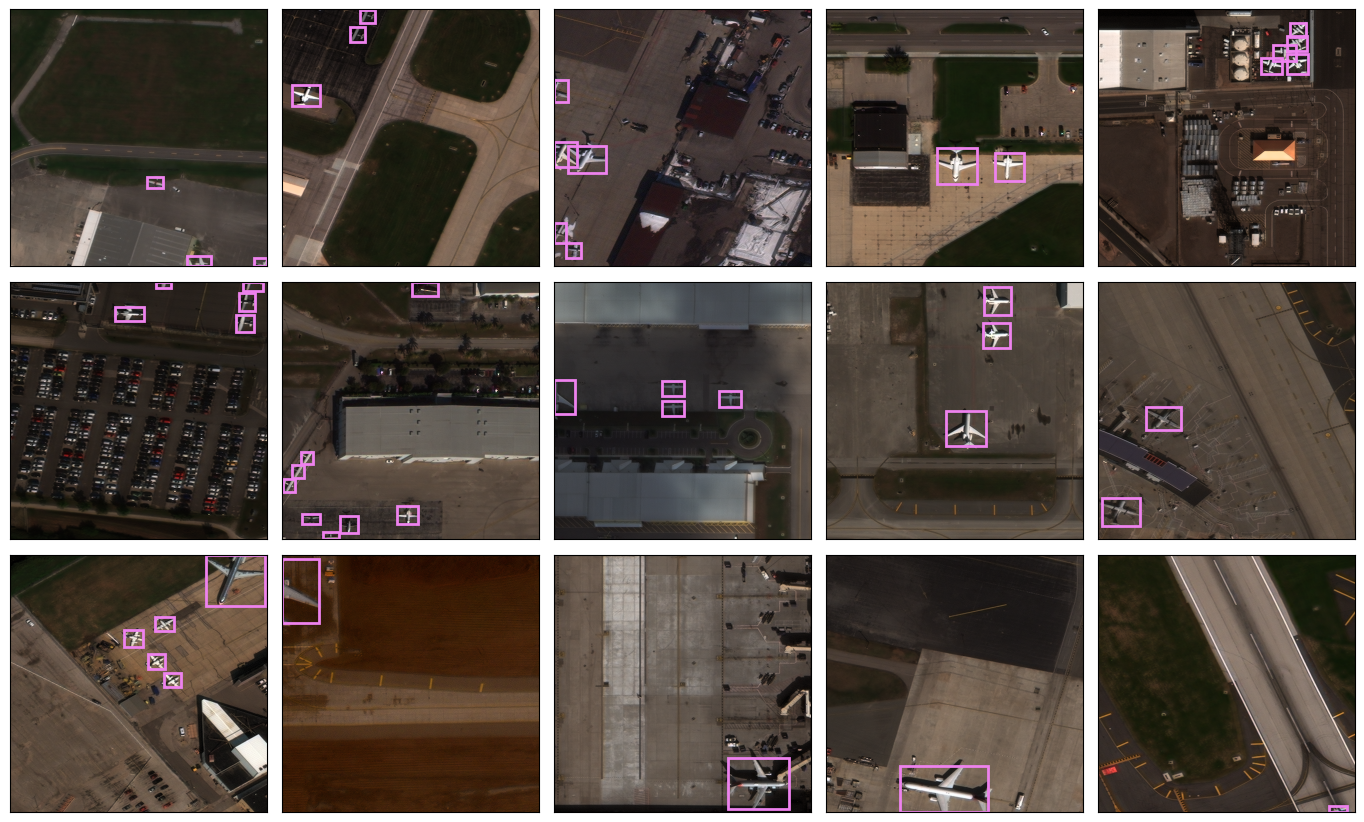

In [8]:
dataset.show_batch(15);

In [38]:
dataset.data_distribution_table()

,Label,Count
0,Airplane,18393


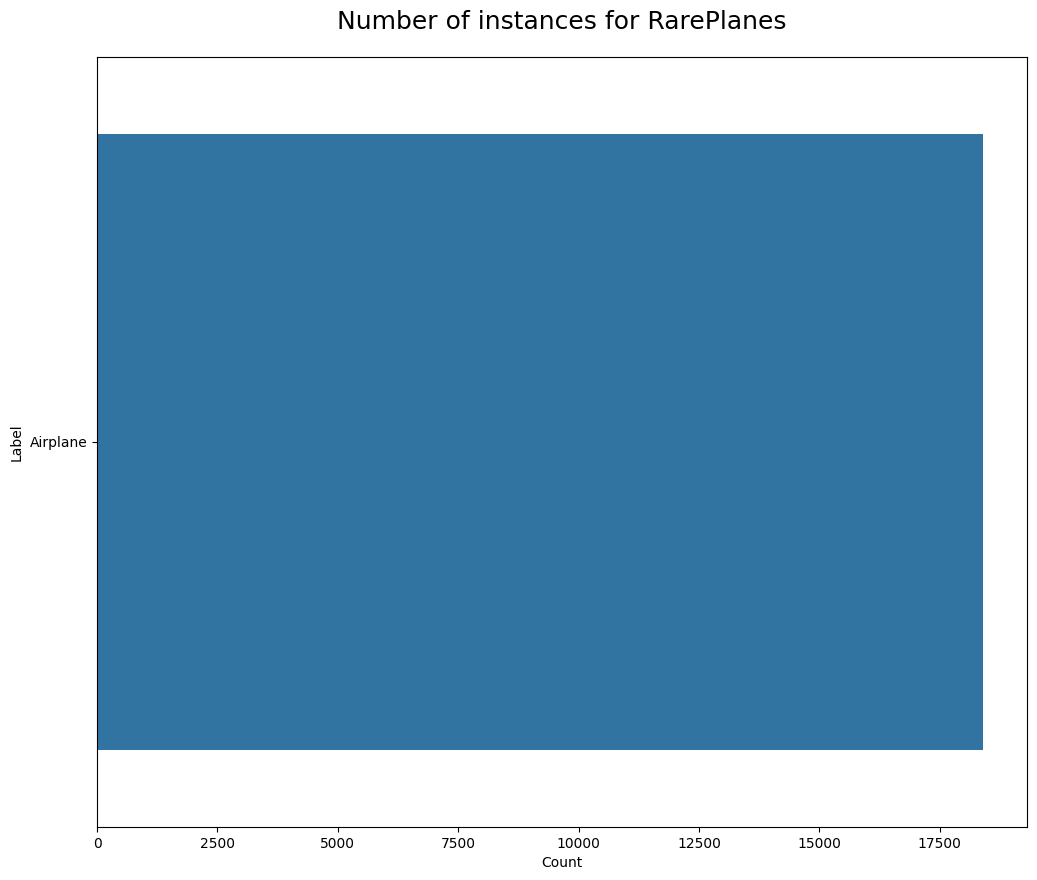

In [39]:
dataset.data_distribution_barchart();

## Load train data

In [44]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/RarePlanes/train/PS-RGB_tiled",
    "annotation_dir": "/home/dragik/data/FAIR_EO/RarePlanes/train/geojson_aircraft_tiled",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = RarePlanesDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 5815


## Create the model

In [45]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/RarePlanes/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [46]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-18 06:50:54,920 INFO Starting training.
training: 100%|██████████| 727/727 [05:45<00:00,  2.10it/s]
2025-09-18 06:56:41,185 INFO epoch: 1, time: 346, loss:  0.17507
testing on train set: 100%|██████████| 727/727 [03:24<00:00,  3.56it/s]
2025-09-18 07:00:16,815 INFO map:0.7955968976020813, map_50:0.9874406456947327, map_75:0.9438860416412354, map_small:0.7622362971305847, map_medium:0.809598982334137, map_large:0.8691248297691345, mar_1:0.2719458341598511, mar_10:0.7532539367675781, mar_100:0.8300603628158569, mar_small:0.806396484375, mar_medium:0.8417613506317139, mar_large:0.8993051648139954, map_per_class:0.7955968976020813, mar_100_per_class:0.8300603628158569, classes:1.0
training: 100%|██████████| 727/727 [05:38<00:00,  2.15it/s]
2025-09-18 07:05:55,044 INFO epoch: 2, time: 339, loss:  0.11465
testing on train set: 100%|██████████| 727/727 [03:02<00:00,  3.98it/s]
2025-09-18 07:09:07,139 INFO map:0.8080126047134399, map_50:0.9888742566108704, map_75:0.9669879674911499, ma

0.04508330964596233

## Evaluate the model

In [47]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/RarePlanes/test/PS-RGB_tiled",
    "annotation_dir": "/home/dragik/data/FAIR_EO/RarePlanes/test/geojson_aircraft_tiled",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = RarePlanesDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 2710


2025-09-18 11:30:20,537 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar
2025-09-18 11:30:20,927 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 339/339 [01:35<00:00,  3.56it/s]


[{'map': 0.7878082394599915,
  'map_50': 0.9587167501449585,
  'map_75': 0.9142952561378479,
  'map_small': 0.725685179233551,
  'map_medium': 0.773079514503479,
  'map_large': 0.8866857290267944,
  'mar_1': 0.3414415717124939,
  'mar_10': 0.7658984065055847,
  'mar_100': 0.8163241147994995,
  'mar_small': 0.7628017067909241,
  'mar_medium': 0.8086374402046204,
  'mar_large': 0.9143869876861572,
  'map_per_class': 0.7878082394599915,
  'mar_100_per_class': 0.8163241147994995,
  'classes': 1.0}]

## Predictions

2025-09-18 11:34:39,935 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar
2025-09-18 11:34:40,302 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar at epoch 11


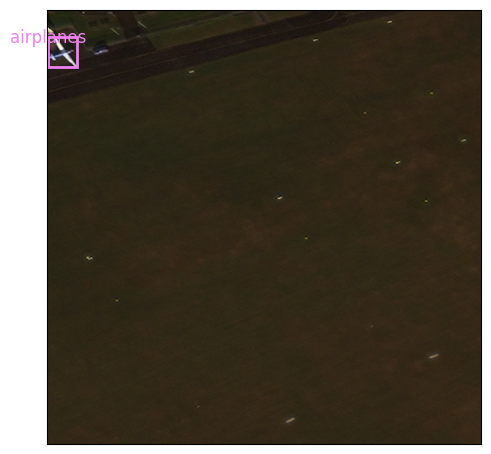

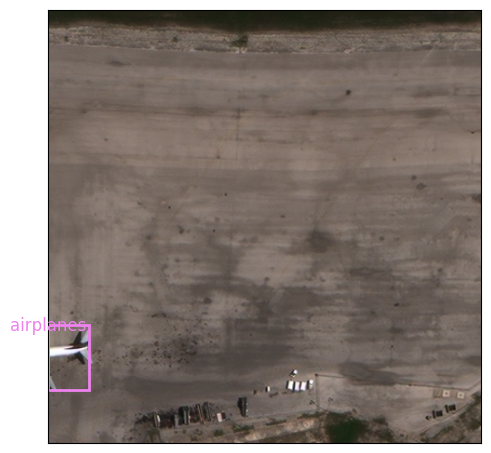

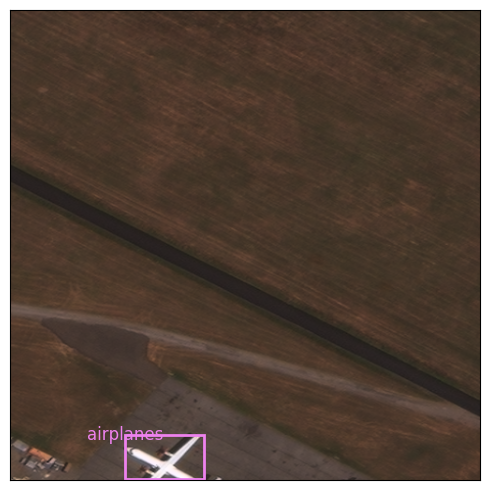

In [48]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/RarePlanes/checkpoint.pth.tar"
labels = ["no-data", "airplanes"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/RarePlanes/test/PS-RGB_tiled/2_1040010024CD5300_tile_30.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/RarePlanes/test/PS-RGB_tiled/5_104001000156CC00_tile_225.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/RarePlanes/test/PS-RGB_tiled/10_104001002E88FE00_tile_74.png')
fig = model.detect_objects(image, labels, transform)